In [ ]:
import gzip
import numpy as np
import matplotlib.pyplot as plt

# Đọc file anh:
def load_images(path):
    f = gzip.open(path, 'rb')
    data = np.frombuffer(f.read(), dtype=np.uint8, offset=16)
    f.close()
    return data.reshape(-1, 784) / 255.0

def load_labels(path):
    f = gzip.open(path, 'rb')
    data = np.frombuffer(f.read(), dtype=np.uint8, offset=8)
    f.close()
    return data

X_train = load_images('mnist_data/train-images-idx3-ubyte.gz')
y_train = load_labels('mnist_data/train-labels-idx1-ubyte.gz')
X_test = load_images('mnist_data/t10k-images-idx3-ubyte.gz')
y_test = load_labels('mnist_data/t10k-labels-idx1-ubyte.gz')

print('Train:', X_train.shape, y_train.shape)
print('Test:', X_test.shape, y_test.shape)

### Assignment 1 (4 scores):

- Use Numpy only to construct the Logistic Regression model.
- Train and evaluating (precision, recall, f1) the Logistic Regression model using the Gradient Descent approach **to classify 0 and 1 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [ ]:
# Lay anh 0 va 1
train_mask = (y_train == 0) | (y_train == 1)
test_mask = (y_test == 0) | (y_test == 1)

X1_train = X_train[train_mask]
y1_train = y_train[train_mask]
X1_test = X_test[test_mask]
y1_test = y_test[test_mask]

print(X1_train.shape, X1_test.shape)

In [4]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

# Khoi tao trong so bang 0
w = np.zeros(784)
b = 0
lr = 0.01
epochs = 100
loss_list = []

for epoch in range(epochs):
    y_hat = sigmoid(X1_train.dot(w) + b)

    # Tính loss (binary cross-entropy)
    loss = -np.mean(y1_train * np.log(y_hat + 1e-9) + (1 - y1_train) * np.log(1 - y_hat + 1e-9))
    loss_list.append(loss)

    # Tính gradient:
    dw = X1_train.T.dot(y_hat - y1_train) / len(y1_train)
    db = np.mean(y_hat - y1_train)

    # Cap nhat trong so
    w = w - lr * dw
    b = b - lr * db

    if epoch % 10 == 0:
        print('Epoch', epoch, 'Loss', round(loss, 4))

Epoch 0 Loss 0.6931
Epoch 10 Loss 0.4673


Epoch 20 Loss 0.3512
Epoch 30 Loss 0.2805
Epoch 40 Loss 0.2336
Epoch 50 Loss 0.2005


Epoch 60 Loss 0.1759
Epoch 70 Loss 0.1571


Epoch 80 Loss 0.1421
Epoch 90 Loss 0.13


In [5]:
#Du doan tren tap test
y1_pred = (sigmoid(X1_test.dot(w) + b) >= 0.5).astype(int)

tp = np.sum((y1_pred == 1) & (y1_test == 1))
fp = np.sum((y1_pred == 1) & (y1_test == 0))
fn = np.sum((y1_pred == 0) & (y1_test == 1))

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print('Precision:', round(precision, 4))
print('Recall:', round(recall, 4))
print('F1-score:', round(f1, 4))
print('Accuracy:', round(np.mean(y1_pred == y1_test), 4))

Precision: 0.9974
Recall: 0.9991
F1-score: 0.9982
Accuracy: 0.9981


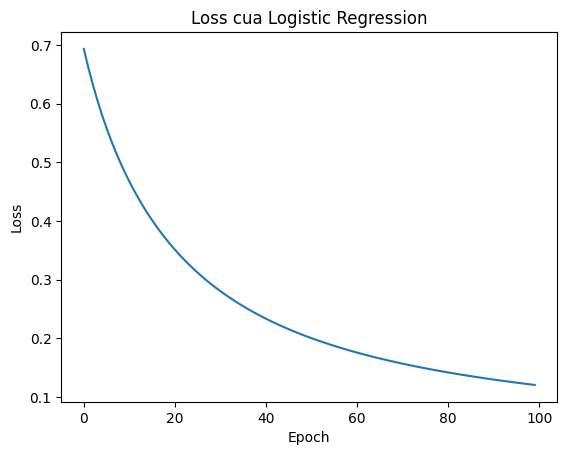

In [6]:
plt.plot(loss_list)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss cua Logistic Regression')
plt.show()

### Assignment 2 (4 scores):

- Use Numpy only to construct the Softmax Regression model.
- Train and evaluating (precision, recall, f1) the Softmax Regression model using the Gradient Descent approach **to classify 10 digit images** on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Visualize the loss function of the training process.

In [7]:
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    e = np.exp(z)
    return e / np.sum(e, axis=1, keepdims=True)

# Doi nhan sang dang One-Hot
Y_train = np.zeros((len(y_train), 10))
Y_train[np.arange(len(y_train)), y_train] = 1

W = np.zeros((784, 10))
b2 = np.zeros(10)
lr = 0.1
epochs = 100
loss_list2 = []

for epoch in range(epochs):
    y_hat = softmax(X_train.dot(W) + b2)

    # Cross-entropy loss
    loss = -np.mean(np.sum(Y_train * np.log(y_hat + 1e-9), axis=1))
    loss_list2.append(loss)

    # Gradient
    dW = X_train.T.dot(y_hat - Y_train) / len(y_train)
    db = np.mean(y_hat - Y_train, axis=0)

    W = W - lr * dW
    b2 = b2 - lr * db

    if epoch % 10 == 0:
        print('Epoch', epoch, 'Loss', round(loss, 4))

Epoch

 0 Loss 2.3026


Epoch 10 Loss 1.5463


Epoch 20 Loss 1.1861


Epoch 30 Loss 0.9934


Epoch 40 Loss 0.8755


Epoch 50 Loss 0.796


Epoch 60 Loss 0.7384


Epoch 70 Loss 0.6947


Epoch 80 Loss 0.6601


Epoch 90 Loss 0.6321


In [8]:
# Du doan: Lay lop co xac suat lon nhat
y2_pred = np.argmax(softmax(X_test.dot(W) + b2), axis=1)

p_list = []
r_list = []
f_list = []

# Tinh precision, recall, f1
for c in range(10):
    tp = np.sum((y2_pred == c) & (y_test == c))
    fp = np.sum((y2_pred == c) & (y_test != c))
    fn = np.sum((y2_pred != c) & (y_test == c))

    p = tp / (tp + fp)
    r = tp / (tp + fn)
    f = 2 * p * r / (p + r)

    p_list.append(p)
    r_list.append(r)
    f_list.append(f)
    print('So', c, '- Precision:', round(p, 4), 'Recall:', round(r, 4), 'F1:', round(f, 4))

print()
print('Macro Precision:', round(np.mean(p_list), 4))
print('Macro Recall:', round(np.mean(r_list), 4))
print('Macro F1-score:', round(np.mean(f_list), 4))
print('Accuracy:', round(np.mean(y2_pred == y_test), 4))

So 0 - Precision: 0.9079 Recall: 0.9653 F1: 0.9357
So 1 - Precision: 0.9037 Recall: 0.9595 F1: 0.9308
So 2 - Precision: 0.8904 Recall: 0.8188 F1: 0.8531
So 3 - Precision: 0.8453 Recall: 0.8713 F1: 0.8581
So 4 - Precision: 0.8624 Recall: 0.8809 F1: 0.8715
So 5 - Precision: 0.8737 Recall: 0.7287 F1: 0.7946
So 6 - Precision: 0.8781 Recall: 0.9175 F1: 0.8974
So 7 - Precision: 0.9007 Recall: 0.8648 F1: 0.8824
So 8 - Precision: 0.809 Recall: 0.8306 F1: 0.8197
So 9 - Precision: 0.8317 Recall: 0.8474 F1: 0.8395

Macro Precision: 0.8703
Macro Recall: 0.8685
Macro F1-score: 0.8683
Accuracy: 0.8707


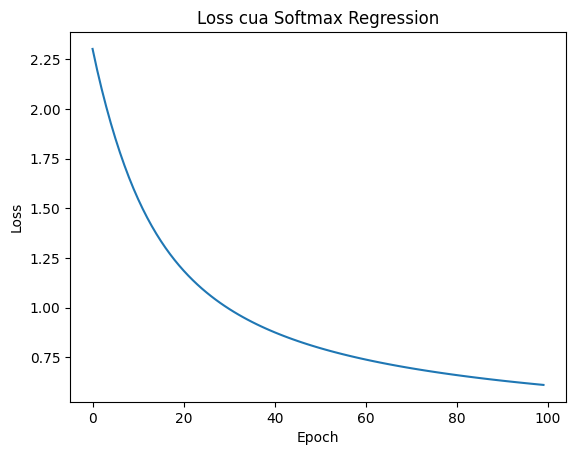

In [9]:
plt.plot(loss_list2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Loss cua Softmax Regression')
plt.show()

### Assignment 3 (2 scores):

- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Logistic Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.
- Use a Machine Learning library (Scikit Learn or Skorch) to implement and evaluate the Softmax Regression on the [MNIST](https://github.com/cvdfoundation/mnist?tab=readme-ov-file) dataset.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# Logistic Regression: phan loai số 0 và 1
model1 = LogisticRegression(max_iter=1000)
model1.fit(X1_train, y1_train)
pred1 = model1.predict(X1_test)

print('Logistic Regression (0 va 1)')
print(classification_report(y1_test, pred1, digits=4))

NameError: name 'X1_train' is not defined

In [13]:
# Softmax Regression: phan loai 10 chu so
model2 = LogisticRegression(max_iter=1000)
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)

print('Softmax Regression (10 chu so)')
print(classification_report(y_test, pred2, digits=4))

KeyboardInterrupt: 